## NFL TEAM FOUNDING YEAR

Kevin Ku

November 12 2026



I am doing NFL team dataset. I got it from https://jsonlint.com/datasets.

I chose this data because it about football. I am interest in learnning about more about NFL team histroy includes where they are found. Which confrence they belong too.

Each observation will represent one NFL team. Which will include the team's name,city,state,conference,division,founding yeat,staduim, and primary color.

The variable I am plan to invsite is founding years of a NFL team nd compare it with different teams were established.

My research question is what year most NFL teams found

My hypothesis is NFL were found between 1950s-1970s because professional football expanded during that year.


In [210]:
import json 
import pandas as pd

with open("sports-teams-nfl.json") as file:

    data=json.load(file)

import matplotlib.pyplot as plt

import statsmodels.formula.api as smf





I loaded my NFL dataset to Hupyter Notebook using JSON Library. The dataset contains information about 32 NFL teams. 

In [211]:
df= pd.DataFrame(data["teams"])

In [212]:
df.head()

,name,abbreviation,city,state,conference,division,founded,stadium,primary_color
0,Arizona Cardinals,ARI,Glendale,Arizona,NFC,West,1898,State Farm Stadium,#97233F
1,Atlanta Falcons,ATL,Atlanta,Georgia,NFC,South,1965,Mercedes-Benz Stadium,#A71930
2,Baltimore Ravens,BAL,Baltimore,Maryland,AFC,North,1996,M&T Bank Stadium,#241773
3,Buffalo Bills,BUF,Orchard Park,New York,AFC,East,1960,Highmark Stadium,#00338D
4,Carolina Panthers,CAR,Charlotte,North Carolina,NFC,South,1993,Bank of America Stadium,#0085CA


I use df.head() to show first five rows of my NFL dataset. It helps me understand my data better.

In [213]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           32 non-null     str  
 1   abbreviation   32 non-null     str  
 2   city           32 non-null     str  
 3   state          32 non-null     str  
 4   conference     32 non-null     str  
 5   division       32 non-null     str  
 6   founded        32 non-null     int64
 7   stadium        32 non-null     str  
 8   primary_color  32 non-null     str  
dtypes: int64(1), str(8)
memory usage: 4.5 KB


I used df.info() to test the structure and data type. My dataset contains 32 NFL teams and 9 columns. Most of the columns have text while the founding year have number data.

In [214]:
df.shape

(32, 9)

In [215]:
df.isnull().sum()

name             0
abbreviation     0
city             0
state            0
conference       0
division         0
founded          0
stadium          0
primary_color    0
dtype: int64

df.isnull().sum() checks for missing values in each column

In [216]:
df.duplicated().sum()

np.int64(0)

This code df.duplicated().sum() is checking for duplicate rows

In [217]:
df["founded"].dtype

dtype('int64')


I checked the founding year column to make sure it has number data. 

Document change and prepration I loaded the NFL JSON file and converted it into a pandas DataFrame. I checked for missing  values, duplicate rows, and incorrect data types. The dataset did not requre change.



## Data Cleaning and Preparation

I loaded my NFL JSON and I change it into pandas DataFfame. I checked the dataset for missing valu, duplicate rows, and wrong data types. The dataset did not require any cleaning. So I kelpt the orginal  value no change. I am going to use founding year column for my histogram analysis.

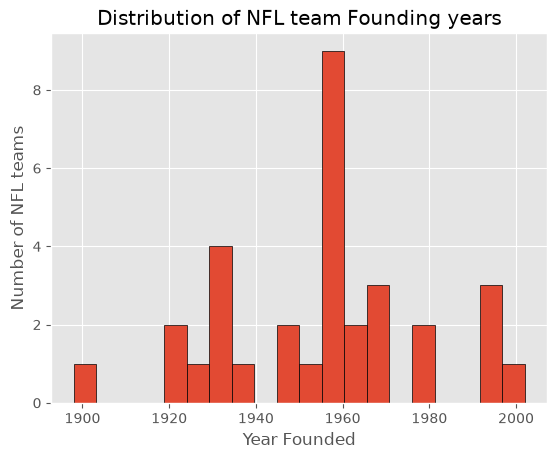

In [218]:
plt.hist(df["founded"], bins=20, edgecolor="black")

plt.title("Distribution of NFL team Founding years")
plt.xlabel("Year Founded")
plt.ylabel("Number of NFL teams")

plt.show()

This graph shows that a lot of NFL teams are founded around the middle of the 1900s. 9 teams in the dataset are founded year are excatly 1960.

## Histogram Analysis

1. My histoogram shows the distribution of NFL teams based on the years they were founded. Most NFL teams were founded during the middle in the 1900s.

2. One of the unsual value is the Arizona Carnails. It established in 1898. This is much earlier than most other NFL teams.

3. I use 10 bins for my histogram. When I use less bins the graph shows more deatils about NFL team foundings.

In [219]:
df["team_age"] = 2026 - df["founded"]

This creates a new column called team_age

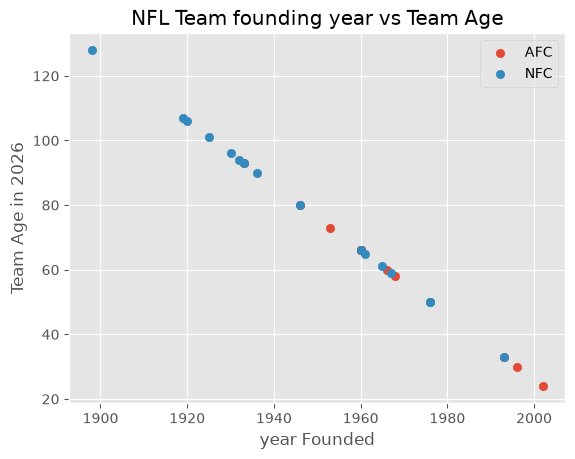

In [220]:
for conference, group in df.groupby("conference"):

    plt.scatter(
        group["founded"],
        group["team_age"],
        label=conference
    )

plt.title("NFL Team founding year vs Team Age")
plt.xlabel("year Founded")
plt.ylabel("Team Age in 2026")
plt.legend()
plt.show()



## Scatter Plot Anaylis

I create a scatter plot comparing the founding years of NFL team with their age in 2026. I use differnet color represnt each team.

It shows a negative relationship. As teams founding years are increasing the age of team decrease. 

The cardnails are oldest teams and Youngest teams is Texans. Both NFC and AFC have the same pattern because it is caculating from founding years.

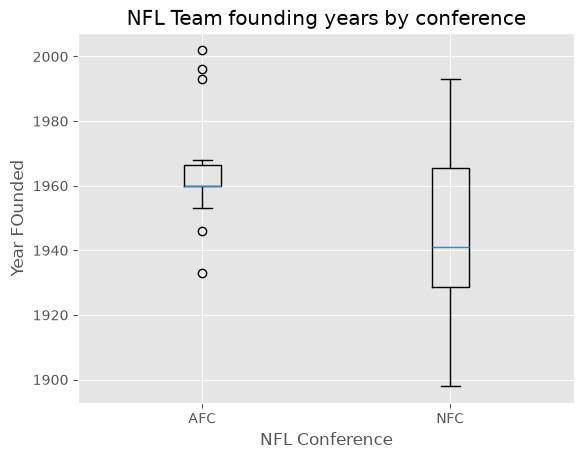

In [221]:
afc=df[df["conference"]=="AFC"]["founded"]
nfc=df[df["conference"]=="NFC"]["founded"]

plt.boxplot([afc,nfc], tick_labels=["AFC","NFC"])

plt.title("NFL Team founding years by conference")
plt.xlabel("NFL Conference")
plt.ylabel("Year FOunded")

plt.show()


## Box plot

I created boxplot to shows that the AFC has a median founding year of 1960, while the NFL has a median of 1941. The box plot shows that NFL teams are much earlier founding years than AFC teams.

In [222]:
plt.style.use("ggplot")

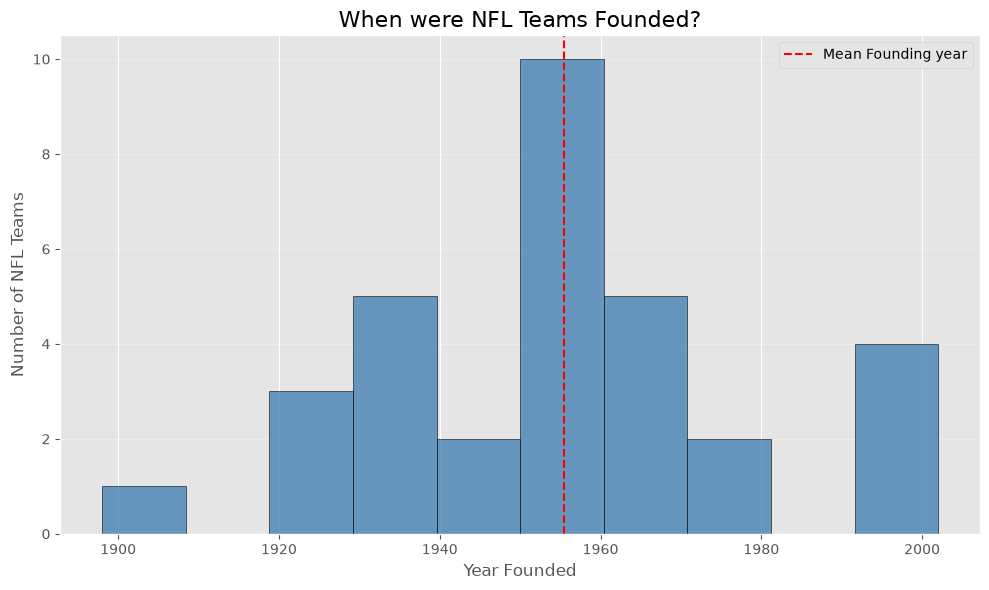

In [223]:
plt.figure(figsize=(10,6))

plt.hist(

    df["founded"],
    bins=10,
    color="steelblue",
    edgecolor="black",
    alpha=0.8
)

plt.axvline(

    df["founded"].mean(),
    color="red",
    linestyle="--",
    label= "Mean Founding year"
    
)

plt.title("When were NFL Teams Founded?", fontsize=16)
plt.xlabel("Year Founded", fontsize=12)
plt.ylabel("Number of NFL Teams", fontsize=12)

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()




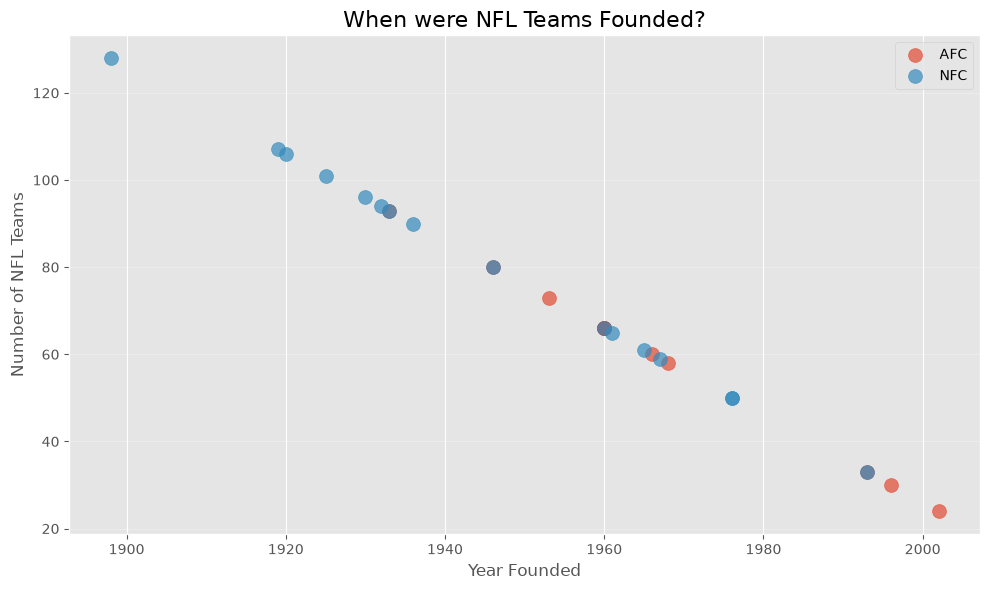

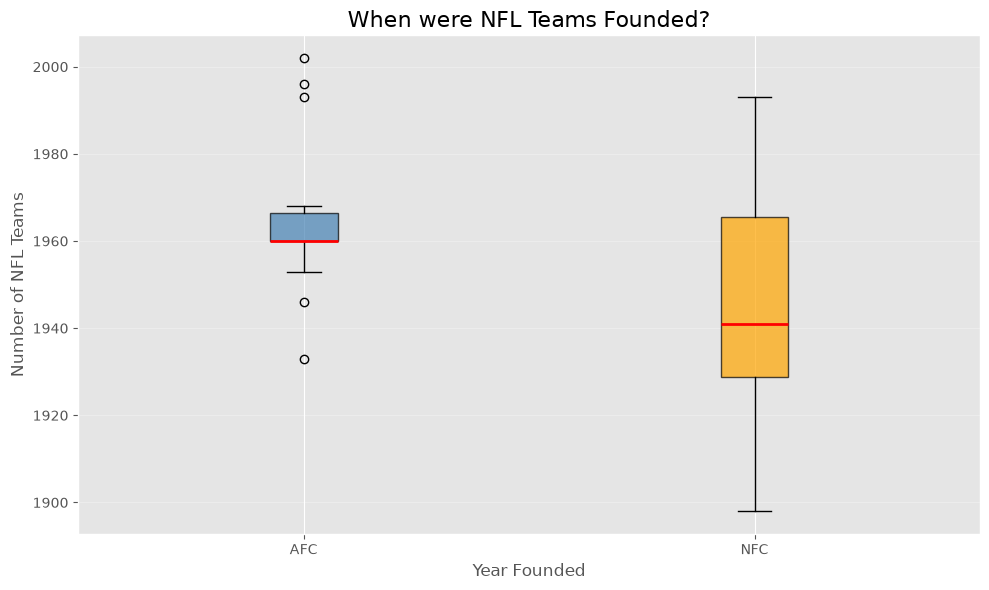

In [224]:

plt.figure(figsize=(10,6))

for conference, group in df.groupby("conference"):

    plt.scatter(
        group["founded"],
        group["team_age"],
        label=conference,
        s=100,
        alpha=0.7
    )



plt.title("When were NFL Teams Founded?", fontsize=16)
plt.xlabel("Year Founded", fontsize=12)
plt.ylabel("Number of NFL Teams", fontsize=12)

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

afc=df[df["conference"]=="AFC"]["founded"]
nfc=df[df["conference"]=="NFC"]["founded"]


plt.figure(figsize=(10,6))

bp = plt.boxplot(

    [afc,nfc],
    tick_labels=["AFC","NFC"],
    patch_artist=True,
    medianprops={"color":"red","linewidth": 2}
)

color=["steelblue","orange"]

for box, color in zip(bp["boxes"], color):

    box.set_facecolor(color)
    box.set_alpha(0.7)

plt.title("When were NFL Teams Founded?", fontsize=16)
plt.xlabel("Year Founded", fontsize=12)
plt.ylabel("Number of NFL Teams", fontsize=12)


plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


I use Matplotlib to improve my three NFL visulization. I use the ggplot style o make all three graph nicer. I increase the figure sizes to make the graphs easier to read.

For histogram I use blue bars and added a red line to show the average fouding year of NFL teams.

For scatter plot I increase the size of the dots and used different colors to represent the AFC and NFC conference. 


For boxplot I used blue and orange color to tell apart AFC and NFC. I also changed median lines to red to make them easier to identify. 

I added titles, axis labels, legends where needed, and gridlines t improve the readility of my graphs. 


## Design Descions ##

I made multiple change to my three NFL visualizations to make them easier to read and understand. 

For historgram I changed the bars blue and I added a red dashed line to show averge founding year of NFL teams were founded.

For scatter plot, Imade the dots larger and used different colors to represent the AFC and NFC conferences. I also added a legend so people can tell which dot represnet each conference

For Boxplot, I used blue for the AFC and orange for the NFC. I also chaged the median lines to red so the audience could easily compare the middle founding years to both conferences. 

Overall these changes make my graph easier to read and help the audience compare information about NFL teams.

In [225]:

    model = smf.ols(
    
        "founded ~ C(conference)",
        data=df

    ).fit()

    print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                founded   R-squared:                       0.158
Model:                            OLS   Adj. R-squared:                  0.130
Method:                 Least Squares   F-statistic:                     5.642
Date:                Thu, 12 Nov 2026   Prob (F-statistic):             0.0241
Time:                        10:58:58   Log-Likelihood:                -143.76
No. Observations:                  32   AIC:                             291.5
Df Residuals:                      30   BIC:                             294.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept             1964.8125 

## CONCLUSION and REFLECTION

What I learn from my dataset is that NFL teams were founded during many different years. Many NFL teams were founded around the middle of the 1900s.

My orginal hypothesis was that most NFL teas were founded between 1950 and 1970. My data showed that 15/32 NFL teams were founded during those years. It was a large group but it was not more than half of the teams. It didn't support my hypothesis fully.

I think historgram is the most effective visualization because it showed when NFL teams were founded. It helped me see which yeard had the most teams and made it easier to understand the distribution.

My statistical analysis reveal anything new because it shows the average founding year of NFC teams was about 19 years ago. The p value was somewhere about 0.024, which it is less than 0.055. It shows that the difference was statistically significanr under the model assumption.


There is is one limatation in my dataset. My dataset only have 32 NFL teams. It focuses on basic team information, such as founding years conferences, divisions, and staduims. 

My analysis didn't show how successful teams have been or how many Super Bowls they have won. It also didn't explain why certain teams were founded during single year. 

I could improve my investigation by adding information about Super Bowl wins, playoff appearances, and team records.

My overall conculsion of my analyzing my NFL dataset helped me understand the history of NFL teams and comare their founding years. The histogram showed when teams were founded, the boxplot compares AFC and NFC teams, and the statistical analysis showed a important ffference in their average founding years. 
